# clock/10 — goal heads vs FV (function-vector) heads

Do the **goal heads** (trained GoalScope / head-mask set) and the **function-vector heads**
(Todd et al. 2024 localization) coincide, or are they dissociable populations?

1. **Load FV heads** — from either (i) the CMA / AIE sweep (`aie_*.pt`, top-K) or
   (ii) the joint head mask (`head_mask/all_lam*/mask.pt`, thresholded).
2. **FV-effect sanity check** — transplant the top FV heads' mean activation `ā` into a
   *zero-shot* ICL query and check it recovers the target relation's answer, on a few tasks.
   (Canonical Todd et al. FV-recovery test, reusing the CMA transplant primitive
   `forward_with_src_replacement`.)
3. **Dissociation**
   - **3a** location + overlap between FV heads and goal heads (grid plot + Jaccard).
   - **3b** `apply_goalscope` on the *same* code prompt with **only** `selected_heads` swapped
     (FV heads vs goal heads) — qualitative. Oracle-based scale-up deferred.

Setup mirrors `09.1_goalhead_gaze` (32B, eager attention).

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-08-03 13:58:42 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-08-03 13:58:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-03 13:58:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-08-03 13:58:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-03 13:58:42 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-08-03 13:58:43 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-08-03 13:59:07 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-03 13:59:07 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-08-03 13:59:07 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## Head sets — goal heads + FV heads

**Goal heads**: trained localization mask, thresholded @0.9, restricted to the 32B goal band
(layers 25–55), exactly as in `09.1` / `09 §4`.

**FV heads**: `FV_SOURCE` switch — `"cma"` takes the top-`FV_TOPK` heads by AIE; `"mask"` thresholds
the joint FV head mask for a chosen `λ`.

In [3]:
# ── goal heads (trained mask @0.9, 32B band 25-55) ──
GOAL_THRESHOLD = 0.9
GOAL_BAND = (25, 56)                       # keep layers [25, 56); mirrors 09.1
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads (@{GOAL_THRESHOLD}, band {GOAL_BAND[0]}-{GOAL_BAND[1]-1}): {len(goal_heads)}")

goal heads (@0.9, band 25-55): 122


In [4]:
# ── FV heads: CMA top-K  OR  joint-mask threshold ──
FV_SOURCE         = "cma"        # "cma" (top-K AIE) | "mask" (thresholded joint mask)
FV_TOPK           = 150           # cma: number of top-AIE heads (Todd et al. default)
FV_MASK_LAM       = "1"         # mask: which lambda sweep dir (all_lam{LAM})
FV_MASK_THRESHOLD = 0.5          # mask: selection threshold

fv_dir = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "fv", MODEL_NAME.split("/")[-1])
if FV_SOURCE == "cma":
    aie = torch.load(os.path.join(fv_dir, "aie_all_ns10_nt25.pt"),
                     map_location="cpu")["aie"].numpy()                 # (L, H)
    top = np.argsort(aie, axis=None)[::-1][:FV_TOPK]
    fv_heads = [(int(i // N_HEADS), int(i % N_HEADS)) for i in top]
    fv_desc = f"CMA top-{FV_TOPK} AIE"
elif FV_SOURCE == "mask":
    mck = torch.load(os.path.join(fv_dir, "head_mask", f"all_lam{FV_MASK_LAM}", "mask.pt"),
                     map_location="cpu", weights_only=False)
    fv_layers = [int(x) for x in mck["layers"]]
    fmv = mck["mask_values"].numpy()
    fv_heads = [(fv_layers[li], int(h)) for li, h in np.argwhere(fmv > FV_MASK_THRESHOLD)]
    fv_desc = f"mask lam{FV_MASK_LAM} @{FV_MASK_THRESHOLD}"
else:
    raise ValueError(FV_SOURCE)
print(f"FV heads ({fv_desc}): {len(fv_heads)}")
print("  ", ", ".join(f"L{l}H{h}" for l, h in sorted(fv_heads)))

FV heads (CMA top-150 AIE): 150
   L0H33, L29H26, L29H27, L29H29, L35H34, L36H36, L38H9, L38H15, L39H19, L39H36, L40H6, L40H34, L41H1, L41H7, L41H24, L41H26, L41H27, L41H29, L41H33, L41H39, L42H22, L43H1, L43H4, L43H9, L43H12, L43H18, L43H19, L43H20, L43H21, L43H24, L44H0, L44H4, L44H7, L44H9, L44H12, L44H14, L44H16, L44H20, L44H21, L44H22, L44H24, L44H28, L44H38, L45H3, L45H7, L45H12, L45H14, L45H15, L45H18, L45H25, L45H26, L45H27, L45H28, L45H29, L45H32, L45H34, L45H35, L45H37, L46H2, L46H6, L46H9, L46H14, L46H17, L46H18, L46H19, L46H20, L46H22, L46H25, L46H28, L46H29, L46H32, L46H37, L47H1, L47H2, L47H12, L47H15, L47H17, L47H18, L47H21, L47H27, L47H28, L47H30, L47H31, L47H35, L48H1, L48H12, L48H16, L48H19, L48H25, L48H26, L48H30, L48H33, L49H0, L49H5, L49H7, L49H9, L49H26, L49H27, L49H28, L49H31, L50H12, L50H20, L50H21, L50H23, L50H24, L50H31, L50H33, L51H0, L51H10, L51H13, L51H19, L51H22, L51H30, L51H32, L51H33, L52H9, L52H31, L52H32, L54H14, L54H30, L54H36, L54H37, L54H38, L55H20,

## 2. FV-effect sanity check

For a handful of relations, transplant the **top FV heads' mean activation `ā`** (per task,
computed over clean 10-shot ICL prompts) into a **zero-shot** query `Q: x⏎A:` at the last token,
and check the top predicted token flips toward the correct answer. This is the Todd et al.
function-vector recovery test, using the same `forward_with_src_replacement` head-transplant
primitive the CMA localization uses.

Reports, per task: **clean** vs **patched** top-1 accuracy and mean Δp(correct), plus a few
concrete `input → (clean top | patched top)` examples.

In [5]:
from scripts.fv.fv_common import list_abstractive_tasks
list_abstractive_tasks()

['ag_news',
 'antonym',
 'capitalize',
 'capitalize_first_letter',
 'capitalize_last_letter',
 'capitalize_second_letter',
 'commonsense_qa',
 'country-capital',
 'country-currency',
 'english-french',
 'english-german',
 'english-spanish',
 'landmark-country',
 'lowercase_first_letter',
 'lowercase_last_letter',
 'national_parks',
 'next_capital_letter',
 'next_item',
 'park-country',
 'person-instrument',
 'person-occupation',
 'person-sport',
 'present-past',
 'prev_item',
 'product-company',
 'sentiment',
 'singular-plural',
 'synonym',
 'word_length']

In [6]:
from scripts.fv.fv_common import (load_fv_task, build_icl_prompt,
                                   first_answer_token_id, compute_mean_head_activations)
from src.goals.head_loc_attn import HeadMask, forward_with_src_replacement
from src.tokens import prepare_input

FV_TASKS    = ["antonym", "present-past", "singular-plural", "country-capital", "landmark-country", "sentiment"]
N_QUERY     = 32         # zero-shot queries per task
MEAN_TRIALS = 32         # clean ICL prompts for a-bar per task
FV_LAYERS   = list(range(N_LAYER))

# binary HeadMask (1.0 at the FV heads) over all layers
fv_mask = HeadMask(N_LAYER, N_HEADS)
with torch.no_grad():
    fv_mask.values.zero_()
    for (l, h) in fv_heads: fv_mask.values[l, h] = 1.0

def zero_shot(x): return build_icl_prompt([], x)          # "\n\nQ: x\nA:"

rows = []
for t in FV_TASKS:
    task = load_fv_task(t, seed=42)
    a_bar = compute_mean_head_activations(mt, task, FV_LAYERS, n_shots=10,
                                          n_trials=MEAN_TRIALS, batch_size=16, seed=42)  # (L, n_embd)
    qs = task.valid[:N_QUERY]
    clean_hit = patch_hit = 0; dp_sum = 0.0; ex = []
    for q in qs:
        prompt = zero_shot(q["input"])
        tid = first_answer_token_id(mt, prompt, q["output"])
        inp = prepare_input(prompts=prompt, tokenizer=mt)
        with torch.inference_mode():
            cl = mt._model(**dict(inp)).logits[:, -1, :].float()
            pl = forward_with_src_replacement(mt, inp, a_bar, fv_mask, layers=FV_LAYERS,
                                              alpha=1.0, patch_positions=[-1]).float()
        if pl.ndim == 1: pl = pl.unsqueeze(0)
        cp = torch.softmax(cl, -1)[0]; pp = torch.softmax(pl, -1)[0]
        clean_hit += int(cp.argmax().item() == tid)
        patch_hit += int(pp.argmax().item() == tid)
        dp_sum += float(pp[tid].item() - cp[tid].item())
        if len(ex) < 3:
            ex.append((q["input"], q["output"],
                       mt.tokenizer.decode([cp.argmax().item()]).strip(),
                       mt.tokenizer.decode([pp.argmax().item()]).strip()))
    rows.append(dict(task=t, n=len(qs), clean=clean_hit/len(qs), patch=patch_hit/len(qs),
                     dP=dp_sum/len(qs), ex=ex))
    logger.info(f"[{t}] clean {clean_hit}/{len(qs)}  patch {patch_hit}/{len(qs)}")

tbl = Table(title=f"FV recovery ({fv_desc}) — zero-shot query + FV transplant")
for c in ["task", "n", "clean top-1", "patch top-1", "mean dP(correct)"]:
    tbl.add_column(c, justify=("left" if c == "task" else "right"))
for r in rows:
    tbl.add_row(r["task"], str(r["n"]), f"{r['clean']:.2f}", f"{r['patch']:.2f}", f"{r['dP']:+.3f}")
rich_print(tbl)
for r in rows:
    rich_print(f"[bold]{r['task']}[/bold]")
    for x, y, c, p in r["ex"]:
        rich_print(f"   {x!r} -> correct={y!r}   clean={c!r}   patch={p!r}")

2026-08-03 13:59:17 __main__ INFO     [antonym] clean 2/32  patch 12/32
2026-08-03 13:59:26 __main__ INFO     [present-past] clean 0/32  patch 31/32
2026-08-03 13:59:36 __main__ INFO     [singular-plural] clean 2/32  patch 32/32
2026-08-03 13:59:46 __main__ INFO     [country-capital] clean 3/32  patch 17/32
2026-08-03 13:59:55 __main__ INFO     [landmark-country] clean 0/32  patch 1/32
2026-08-03 14:00:06 __main__ INFO     [sentiment] clean 0/32  patch 17/32


    FV recovery (CMA top-150 AIE) — zero-shot query + FV transplant     
┏━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ task             ┃  n ┃ clean top-1 ┃ patch top-1 ┃ mean dP(correct) ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ antonym          │ 32 │        0.06 │        0.38 │           +0.307 │
│ present-past     │ 32 │        0.00 │        0.97 │           +0.918 │
│ singular-plural  │ 32 │        0.06 │        1.00 │           +0.883 │
│ country-capital  │ 32 │        0.09 │        0.53 │           +0.418 │
│ landmark-country │ 32 │        0.00 │        0.03 │           +0.036 │
│ sentiment        │ 32 │        0.00 │        0.53 │           +0.370 │
└──────────────────┴────┴─────────────┴─────────────┴──────────────────┘

antonym

'comic' -> correct='tragic'   clean='A'   patch='cartoon'

'transparent' -> correct='opaque'   clean='Transparent'   patch='opaque'

'fore' -> correct='aft'   clean='It'   patch='aft'

... (16 outputs left out)

sentiment

'Russian Ark is a new treasure of the Hermitage.' -> correct='positive'   clean='Yes'   patch='True'

"As steamy as last week's pork dumplings." -> correct='negative'   clean='This'   patch='This'

'...hypnotically dull.' -> correct='negative'   clean='The'   patch='negative'

## 3a. Location + overlap between FV heads and goal heads

goal heads: 122  FV heads: 150  intersection: 23  union: 249  Jaccard: 0.092


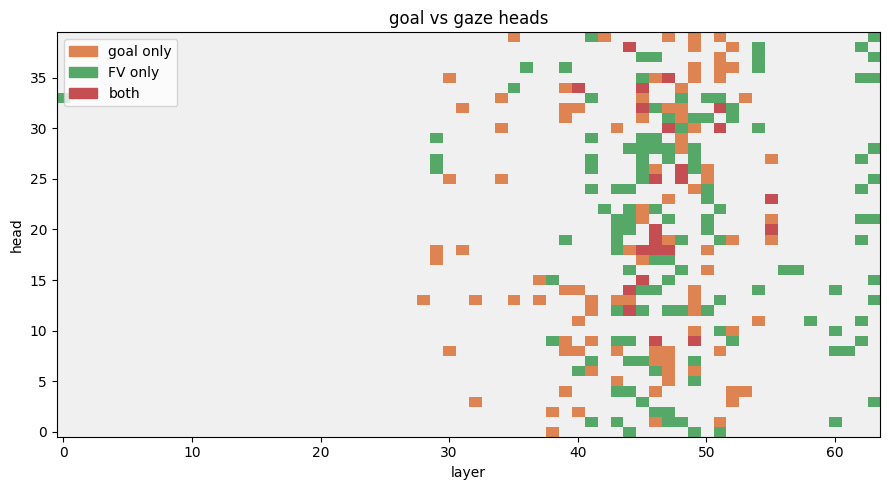

                                              goal vs FV head overlap                                              
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ metric        ┃                                                                                           value ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ goal heads    │                                                                                             122 │
│ FV heads      │                                                                                             150 │
│ intersection  │                                                                                              23 │
│ union         │                                                                                             249 │
│ Jaccard       │                                                                                           0.092 │
│ overlap heads │  L40H34, L44H12, L44H14, L44H38, L45H15, L45H18, L45H32, L45H34, L46H9, L46H18, L46H19, L46H20, │
│               │           L46H25, L47H18, L47H30, L47H35, L48H25, L48H26, L49H9, L51H30, L51H32, L55H20, L55H23 │
└───────────────┴─────────────────────────────────────────────────────────────────────────────────────────────────┘

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

gset, fset = set(goal_heads), set(fv_heads)
inter, union = gset & fset, gset | fset
jacc = len(inter) / len(union) if union else 0.0
print(f"goal heads: {len(gset)}  FV heads: {len(fset)}  intersection: {len(inter)}  union: {len(union)}  Jaccard: {jacc:.3f}")

grid = np.zeros((N_LAYER, N_HEADS))
for (l, h) in goal_heads: grid[l, h] += 1        # 1 = goal
for (l, h) in fv_heads:   grid[l, h] += 2        # 2 = FV, 3 = both
cmap = ListedColormap(["#f0f0f0", "#dd8452", "#55a868", "#c44e52"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.T, aspect="auto", cmap=cmap, vmin=0, vmax=3, origin="lower")
ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title("goal vs gaze heads")
ax.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                   [("#dd8452","goal only"),("#55a868","FV only"),("#c44e52","both")]], loc="upper left")
plt.tight_layout(); plt.show()


ot = Table(title="goal vs FV head overlap")
ot.add_column("metric"); ot.add_column("value", justify="right")
ot.add_row("goal heads", str(len(goal_heads)))
ot.add_row("FV heads", str(len(fv_heads)))
ot.add_row("intersection", str(len(inter)))
ot.add_row("union", str(len(union)))
ot.add_row("Jaccard", f"{jacc:.3f}")
ot.add_row("overlap heads", ", ".join(f"L{l}H{h}" for l, h in sorted(inter)) or "—")
rich_print(ot)

## 3b. GoalScope — swap **only** the heads (FV vs goal)

One shared code prompt + generation, one shared `GOALSCOPE_KWARGS` dict (tweak freely). The two
runs differ **only** in `selected_heads`: FV heads vs goal heads. `strategy="replace"` steers each
set at its *own* layers. Eyeball the two token-hover verbalizations for a qualitative dissociation;
Oracle-based scale-up comes later.

In [28]:
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.functional import generate_with_patch
from rich.markup import escape

dest_example = build_example(
    mt=mt,
    rng=random.Random(1234),
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="multiline",
    naming="natural"
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_prompt = dest_prompt[: dest_prompt.index("def check_conditions(n: int):")]
print(dest_prompt)

# chunky_sample = next(s for s in chunky_samples if s.spec.datatype == "str")
# dest_prompt = build_prompt(chunky_sample)

dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    



clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the product of n's digits is greater than 0
2. n is a perfect square
3. n is even
4. n is divisible by 4

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n):
    p=1
    for d in str(n):p*=int(d)
    a=p>0
    b=int(n**0.5)**2==n
    c=n%2==0
    d=n%4==0
    print(f"Product of digits > 0: {a}, Perfect square: {b}, Even: {c}, Divisible by 4: {d}, All conditions: {a and
b and c and d}")
</code>

In [29]:
from src.goals.goalscope import apply_goalscope

# ── common GoalScope kwargs — tweak here; ONLY `selected_heads` differs between runs ──
GOALSCOPE_KWARGS = dict(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    strategy="replace", alpha=1.0,
    # strategy="additive", alpha=0.2,
    steer_layer_range=(35, 46),
    batch_size=32,
    max_new_tokens=64,
    show=True,
    include_noncode=True,
)

fv_scope = apply_goalscope(
    selected_heads=sorted(fv_heads),
    title=f"GoalScope — FV heads ({fv_desc})",
    save_path="fv_demo_check_cond.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/4 [00:00<?, ?it/s]

Saved -> fv_demo_check_cond.html


In [30]:
goal_scope = apply_goalscope(
    selected_heads=sorted(goal_heads),
    save_path="goal_demo_check_cond.html",
    title="GoalScope — Goal heads",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/4 [00:00<?, ?it/s]

Saved -> goal_demo_check_cond.html


In [31]:
messages = [
    {"role": "system", "content": "You are a helpful assistant proficient in programming."},
    {"role": "user", "content": "Write a mergesort code in Python. Just the code, no explanation and comments."},
    {"role": "assistant", "content": "\n<code>\n"},
]
dest_prompt = mt.tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=False,
    continue_final_message=True,
    tokenize=False,
    chat_template_kwargs={"enable_thinking": False},
)
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")

clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=256,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean         <|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
Write a mergesort code in Python. Just the code, no explanation and comments.<|im_end|>
<|im_start|>assistant

<code>
def merge_sort(arr):
    if len(arr) > 1:
        mid = len(arr) // 2
        L = arr[:mid]
        R = arr[mid:]

        merge_sort(L)
        merge_sort(R)

        i = j = k = 0

        while i < len(L) and j < len(R):
            if L[i] < R[j]:
                arr[k] = L[i]
                i += 1
            else:
                arr[k] = R[j]
                j += 1
            k += 1

        while i < len(L):
            arr[k] = L[i]
            i += 1
            k += 1

        while j < len(R):
            arr[k] = R[j]
            j += 1
            k += 1
</code>

In [32]:
from src.goals.goalscope import apply_goalscope

# ── common GoalScope kwargs — tweak here; ONLY `selected_heads` differs between runs ──
GOALSCOPE_KWARGS = dict(
    prompt=dest_prompt + clean_gen,
    mt=mt,
    strategy="replace", alpha=1.0,
    # strategy="additive", alpha=0.2,
    steer_layer_range=(35, 46),
    batch_size=32,
    max_new_tokens=64,
    show=True,
    include_noncode=True,
)

fv_scope = apply_goalscope(
    selected_heads=sorted(fv_heads),
    title=f"GoalScope — FV heads ({fv_desc})",
    save_path="fv_demo_merge.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/7 [00:00<?, ?it/s]

Saved -> fv_demo_merge.html


In [ ]:
goal_scope = apply_goalscope(
    selected_heads=sorted(goal_heads),
    title="GoalScope — Goal heads",
    save_path="goal_demo_merge.html",
    **GOALSCOPE_KWARGS,
)

GoalScope[replace]:   0%|          | 0/7 [00:00<?, ?it/s]

Saved -> goal_demo_merge.html


: 

## 4. Do goal heads work as FV heads? — FV recovery through goal vs FV heads

§2 showed the **FV heads** recover the in-context relation when their per-task mean activation `ā` is
transplanted into a zero-shot query. Here we ask the reverse dissociation: route the **same** `ā`
through the **goal** heads instead — do they carry the function-vector effect?

Identical recovery protocol to §2 (same tasks, `ā`, `alpha=1.0`, `patch_positions=[-1]`); **only the
head mask changes** between arms (the §3b principle). Reuses §2's setup — run §2 first. If goal ≠ FV
functionally, the goal-head transplant should recover far less of the relation than the FV-head one.

In [23]:
# ── §4: FV recovery through goal heads vs FV heads — only the head mask changes ──
import pandas as pd

FV_RECOVERY_SETS = {"FV": fv_heads, "goal": goal_heads}

def _binmask(heads):
    m = HeadMask(N_LAYER, N_HEADS)
    with torch.no_grad():
        m.values.zero_()
        for (l, h) in heads: m.values[l, h] = 1.0
    return m
rec_masks = {name: _binmask(hs) for name, hs in FV_RECOVERY_SETS.items()}

rec_rows = []                                   # one row per (task, head-set)
for t in FV_TASKS:
    task = load_fv_task(t, seed=42)
    a_bar = compute_mean_head_activations(mt, task, FV_LAYERS, n_shots=10,
                                          n_trials=MEAN_TRIALS, batch_size=16, seed=42)   # (L, n_embd)
    qs = task.valid[:N_QUERY]
    clean_hit = 0
    agg = {name: dict(patch_hit=0, dp=0.0) for name in FV_RECOVERY_SETS}
    for q in qs:
        prompt = zero_shot(q["input"])
        tid = first_answer_token_id(mt, prompt, q["output"])
        inp = prepare_input(prompts=prompt, tokenizer=mt)
        with torch.inference_mode():
            cl = mt._model(**dict(inp)).logits[:, -1, :].float()
            cp = torch.softmax(cl, -1)[0]
            clean_hit += int(cp.argmax().item() == tid)
            for name, m in rec_masks.items():                 # same a_bar, only the mask differs
                pl = forward_with_src_replacement(mt, inp, a_bar, m, layers=FV_LAYERS,
                                                  alpha=1.0, patch_positions=[-1]).float()
                if pl.ndim == 1: pl = pl.unsqueeze(0)
                pp = torch.softmax(pl, -1)[0]
                agg[name]["patch_hit"] += int(pp.argmax().item() == tid)
                agg[name]["dp"] += float(pp[tid].item() - cp[tid].item())
    for name in FV_RECOVERY_SETS:
        rec_rows.append(dict(task=t, heads=name, n=len(qs), clean=clean_hit / len(qs),
                             patch=agg[name]["patch_hit"] / len(qs), dP=agg[name]["dp"] / len(qs)))
    logger.info(f"[{t}] clean {clean_hit}/{len(qs)}  " +
                "  ".join(f"{name} {agg[name]['patch_hit']}/{len(qs)}" for name in FV_RECOVERY_SETS))

rec_df = pd.DataFrame(rec_rows)
tbl = Table(title="FV recovery through goal vs FV heads (zero-shot query + ā transplant, alpha=1.0)")
for c in ["task", "n", "clean top-1", "FV patch", "goal patch", "FV dP", "goal dP"]:
    tbl.add_column(c, justify=("left" if c == "task" else "right"))
for t in FV_TASKS:
    d = {r["heads"]: r for r in rec_rows if r["task"] == t}
    tbl.add_row(t, str(d["FV"]["n"]), f"{d['FV']['clean']:.2f}",
                f"{d['FV']['patch']:.2f}", f"{d['goal']['patch']:.2f}",
                f"{d['FV']['dP']:+.3f}", f"{d['goal']['dP']:+.3f}")
rich_print(tbl)

2026-08-03 14:36:23 __main__ INFO     [antonym] clean 2/32  FV 12/32  goal 12/32
2026-08-03 14:36:35 __main__ INFO     [present-past] clean 0/32  FV 31/32  goal 8/32
2026-08-03 14:36:46 __main__ INFO     [singular-plural] clean 2/32  FV 32/32  goal 28/32
2026-08-03 14:36:59 __main__ INFO     [country-capital] clean 3/32  FV 17/32  goal 14/32
2026-08-03 14:37:11 __main__ INFO     [landmark-country] clean 0/32  FV 1/32  goal 0/32
2026-08-03 14:37:24 __main__ INFO     [sentiment] clean 0/32  FV 17/32  goal 0/32


 FV recovery through goal vs FV heads (zero-shot query + ā transplant, alpha=1.0) 
┏━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓
┃ task             ┃  n ┃ clean top-1 ┃ FV patch ┃ goal patch ┃  FV dP ┃ goal dP ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩
│ antonym          │ 32 │        0.06 │     0.38 │       0.38 │ +0.307 │  +0.155 │
│ present-past     │ 32 │        0.00 │     0.97 │       0.25 │ +0.918 │  +0.163 │
│ singular-plural  │ 32 │        0.06 │     1.00 │       0.88 │ +0.883 │  +0.546 │
│ country-capital  │ 32 │        0.09 │     0.53 │       0.44 │ +0.418 │  +0.276 │
│ landmark-country │ 32 │        0.00 │     0.03 │       0.00 │ +0.036 │  +0.000 │
│ sentiment        │ 32 │        0.00 │     0.53 │       0.00 │ +0.370 │  +0.001 │
└──────────────────┴────┴─────────────┴──────────┴────────────┴────────┴─────────┘

FV recovery — mean over 6 tasks (clean top-1 
                   = 0.04)                   
┏━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ head set ┃ patch top-1 ┃ mean dP(correct) ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ FV       │        0.57 │           +0.489 │
│ goal     │        0.32 │           +0.190 │
└──────────┴─────────────┴──────────────────┘

goal recovers 53% of the FV top-1 effect (+39% on dP) — 0% = no FV effect, 100% = matches FV heads

saved /disk/u/arnab/Codes/Projects/goals/results/dissociation/Qwen2.5-Coder-32B-Instruct/goal_vs_fv_recovery.png


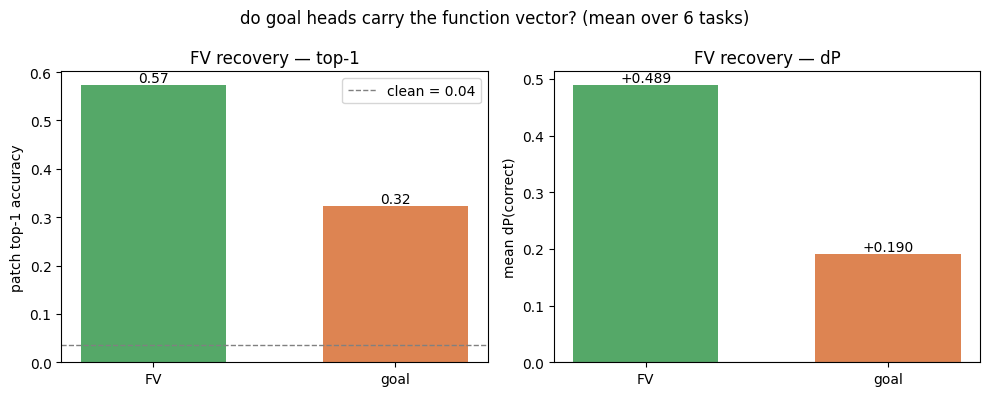

In [15]:
# ── §4 summary: mean over tasks + "goal recovers X% of FV effect" + bar plot ──
SET_COLOR = {"FV": "#55a868", "goal": "#dd8452"}
mean_clean = rec_df.groupby("task").clean.first().mean()
summ = rec_df.groupby("heads").agg(patch=("patch", "mean"), dP=("dP", "mean"))

st = Table(title=f"FV recovery — mean over {len(FV_TASKS)} tasks (clean top-1 = {mean_clean:.2f})")
for c in ["head set", "patch top-1", "mean dP(correct)"]:
    st.add_column(c, justify=("left" if c == "head set" else "right"))
for name in ["FV", "goal"]:
    st.add_row(name, f"{summ.loc[name, 'patch']:.2f}", f"{summ.loc[name, 'dP']:+.3f}")
rich_print(st)

fv_eff   = summ.loc["FV", "patch"] - mean_clean            # top-1 lift over clean
goal_eff = summ.loc["goal", "patch"] - mean_clean
frac_top1 = goal_eff / fv_eff if abs(fv_eff) > 1e-9 else float("nan")
frac_dp = summ.loc["goal", "dP"] / summ.loc["FV", "dP"] if abs(summ.loc["FV", "dP"]) > 1e-9 else float("nan")
if frac_top1 == frac_top1:
    rich_print(f"[bold]goal recovers {frac_top1:.0%} of the FV top-1 effect[/bold] "
               f"({frac_dp:+.0%} on dP) — 0% = no FV effect, 100% = matches FV heads")
else:
    rich_print("[bold]FV arm shows no top-1 lift over clean — recovery ratio undefined[/bold]")

names = ["FV", "goal"]; xs = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
vals = [summ.loc[n, "patch"] for n in names]
axes[0].bar(xs, vals, color=[SET_COLOR[n] for n in names], width=0.6)
axes[0].axhline(mean_clean, ls="--", c="grey", lw=1, label=f"clean = {mean_clean:.2f}")
for x, v in zip(xs, vals): axes[0].text(x, v, f"{v:.2f}", ha="center", va="bottom")
axes[0].set_xticks(xs); axes[0].set_xticklabels(names); axes[0].set_ylabel("patch top-1 accuracy")
axes[0].set_title("FV recovery — top-1"); axes[0].legend()
vals2 = [summ.loc[n, "dP"] for n in names]
axes[1].bar(xs, vals2, color=[SET_COLOR[n] for n in names], width=0.6)
axes[1].axhline(0, c="grey", lw=0.8)
for x, v in zip(xs, vals2): axes[1].text(x, v, f"{v:+.3f}", ha="center", va="bottom" if v >= 0 else "top")
axes[1].set_xticks(xs); axes[1].set_xticklabels(names); axes[1].set_ylabel("mean dP(correct)")
axes[1].set_title("FV recovery — dP")
plt.suptitle(f"do goal heads carry the function vector? (mean over {len(FV_TASKS)} tasks)")
plt.tight_layout()
FIGDIR = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "dissociation", MODEL_NAME.split("/")[-1])
os.makedirs(FIGDIR, exist_ok=True)
FIG4 = os.path.join(FIGDIR, "goal_vs_fv_recovery.png")
plt.savefig(FIG4, dpi=110, bbox_inches="tight"); print("saved", FIG4); plt.show()

In [26]:
task = load_fv_task("antonym", seed=42)
qs = task.valid[:N_QUERY]
qs

[{'input': 'comic', 'output': 'tragic'},
 {'input': 'transparent', 'output': 'opaque'},
 {'input': 'fore', 'output': 'aft'},
 {'input': 'face', 'output': 'back'},
 {'input': 'fictitious', 'output': 'real'},
 {'input': 'ship', 'output': 'dock'},
 {'input': 'reversible', 'output': 'irreversible'},
 {'input': 'distribution', 'output': 'concentration'},
 {'input': 'criminal', 'output': 'law-abiding citizen'},
 {'input': 'contrary', 'output': 'similar'},
 {'input': 'universal', 'output': 'specific'},
 {'input': 'rest', 'output': 'work'},
 {'input': 'support', 'output': 'oppose'},
 {'input': 'mad', 'output': 'sane'},
 {'input': 'shy', 'output': 'outgoing'},
 {'input': 'contraction', 'output': 'expansion'},
 {'input': 'convergence', 'output': 'divergence'},
 {'input': 'virtual', 'output': 'real'},
 {'input': 'west', 'output': 'east'},
 {'input': 'disconnect', 'output': 'connect'},
 {'input': 'soften', 'output': 'harden'},
 {'input': 'slender', 'output': 'plump'},
 {'input': 'disregard', 'outp

In [27]:
zero_shot(qs[0]["input"])

'\n\nQ: comic\nA:'

## 5. Figure 1 replication — does the FV transfer to *natural text*?

Todd et al. Figure 1: an FV extracted from an antonym ICL prompt (`arrive:depart, small:big,
common:`) is dropped into an unrelated natural-text prompt (`The word "fast" means`) and makes the
model emit `slow`. §2/§4 above already showed transfer into a **zero-shot `Q:/A:` query** — the same
scaffold the heads were localized under. This section removes that scaffold entirely: the
destination no longer looks like an ICL prompt at all.

**Source.** The mean activation `ā` over `NT_MEAN_TRIALS` 10-shot ICL prompts — there is no
per-instance source run to speak of. Two variants: `clean` (correct labels) and `shuffled`
(permuted demo labels), the latter being the source-side null — a corrupted `ā` should carry no
task. Eval words are held out of *both* the demo pool and the trailing query of every `ā` prompt.

**Destination.** Two templates per task (`scripts/fv/fv_natural_text.py`), patched at the last
token. Word tasks get the paper's `The word "{x}", means` / `When I think of the word "{x}", it
usually means`; `country-capital` gets the paper's location templates instead, since the "word"
frame does not apply to a place.

**Arms.** clean / FV heads / goal heads / **layer-matched random** heads — the random control has
the same per-layer head count as the FV set, so a null cannot be blamed on depth.

**Two scoring protocols**, per the specs:
1. `acc_first` — scaffolded prompt (`… means "`), top-1 next token must be a non-trivial prefix of
   the target. The scaffold is ours: the paper's own +FV completions open with a quote
   (`The word "limitless", means "finite"`), which a bare first-token check would miss. The clean
   arm sees the same scaffold. `dP` = mean Δp on the contextualized first answer token.
2. `acc_gen` — paper protocol §3.3: unscaffolded template, patch held at the final prompt token
   **and every decode step**, generate 5 tokens, substring-match the target.

Intervention is **replace** (`forward_with_src_replacement`, `alpha=1.0`), consistent with §2/§4 —
*not* the paper's residual-stream addition. If replace comes out flat, the additive fallback goes at
layer ≈ |L|/3 (paper §B.3: layer 9 for GPT-J, 26 for Llama-2-70B); the cell below prints that index.

In [18]:
NT_TASKS       = ["antonym", "present-past", "singular-plural", "country-capital", "landmark-country"]


In [ ]:
# ── §5 config: tasks, head sets (FV / goal / layer-matched random) ──
from scripts.fv.fv_natural_text import (eval_natural_text, layer_matched_random_heads,
                                        templates_for, EDIT_LAYER_FRACTION)

NT_N_QUERY     = 20      # held-out eval words per (task, template)
NT_MEAN_TRIALS = 32      # ICL prompts averaged into a-bar (per task, per source)
NT_MAX_NEW     = 5       # protocol 2: tokens generated with the patch held (paper: 5)
NT_ALPHA       = 1.0
NT_SEED        = 42
NT_SOURCES     = ("clean", "shuffled")

rand_heads   = layer_matched_random_heads(fv_heads, N_HEADS, random.Random(NT_SEED))
NT_HEAD_SETS = {"FV": fv_heads, "goal": goal_heads, "random": rand_heads}

for k, v in NT_HEAD_SETS.items():
    ls = [l for l, _ in v]
    print(f"{k:7s} {len(v):4d} heads   layers {min(ls)}-{max(ls)}")
print()
for t in NT_TASKS:
    print(f"{t:18s} -> " + ", ".join(tp.name for tp in templates_for(t)))
print(f"\nadditive fallback layer (paper |L|/3, only if replace is flat): "
      f"{int(N_LAYER * EDIT_LAYER_FRACTION)}")

FV       150 heads   layers 0-63
goal     122 heads   layers 28-55
random   150 heads   layers 0-63

antonym            -> word-means, word-think
present-past       -> word-means, word-think
singular-plural    -> word-means, word-think
country-capital    -> loc-visit, loc-ago
landmark-country   -> loc-visit, loc-ago
sentiment          -> word-means, word-think

additive fallback layer (paper |L|/3, only if replace is flat): 21


In [20]:
# ── §5 run — (task x template x source x arm); ~a few min per task on 32B ──
nt = eval_natural_text(
    mt, NT_HEAD_SETS, NT_TASKS,
    layers=list(range(N_LAYER)),
    n_query=NT_N_QUERY, n_shots=10, mean_trials=NT_MEAN_TRIALS,
    sources=NT_SOURCES, max_new_tokens=NT_MAX_NEW, alpha=NT_ALPHA,
    seed=NT_SEED, disjoint=True, logger=logger,
)
nt_df = nt.rows
nt_df.head(12)

2026-08-03 14:19:59 __main__ INFO     [antonym] 20 queries (valid=719, train=1679)
2026-08-03 14:21:28 __main__ INFO       [word-means] -/clean 0.00/0.00  clean/FV 0.05/0.10  clean/goal 0.00/0.10  clean/random 0.00/0.00  shuffled/FV 0.10/0.10  shuffled/goal 0.00/0.05  shuffled/random 0.00/0.00
2026-08-03 14:22:53 __main__ INFO       [word-think] -/clean 0.00/0.00  clean/FV 0.00/0.10  clean/goal 0.00/0.00  clean/random 0.00/0.00  shuffled/FV 0.10/0.15  shuffled/goal 0.00/0.00  shuffled/random 0.00/0.00
2026-08-03 14:22:53 __main__ INFO     [present-past] 20 queries (valid=88, train=205)
2026-08-03 14:24:22 __main__ INFO       [word-means] -/clean 0.00/0.00  clean/FV 1.00/0.95  clean/goal 0.00/0.00  clean/random 0.00/0.00  shuffled/FV 0.60/0.15  shuffled/goal 0.00/0.00  shuffled/random 0.00/0.00
2026-08-03 14:25:47 __main__ INFO       [word-think] -/clean 0.00/0.00  clean/FV 1.00/0.90  clean/goal 0.00/0.00  clean/random 0.00/0.00  shuffled/FV 0.55/0.00  shuffled/goal 0.00/0.00  shuffled/

,task,template,source,arm,n,acc_first,acc_gen,dP
0,antonym,word-means,-,clean,20,0.00,0.00,0.000000
1,antonym,word-means,clean,FV,20,0.05,0.10,0.065559
2,antonym,word-means,clean,goal,20,0.00,0.10,0.006391
3,antonym,word-means,clean,random,20,0.00,0.00,-0.000340
4,antonym,word-means,shuffled,FV,20,0.10,0.10,0.046134
5,antonym,word-means,shuffled,goal,20,0.00,0.05,0.011519
6,antonym,word-means,shuffled,random,20,0.00,0.00,0.000031
7,antonym,word-think,-,clean,20,0.00,0.00,0.000000
8,antonym,word-think,clean,FV,20,0.00,0.10,0.066930
9,antonym,word-think,clean,goal,20,0.00,0.00,0.015038


  §5 natural text — first token (prefix), mean over 5   
                         tasks                          
┏━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ template   ┃ source   ┃   FV ┃ goal ┃ random ┃ clean ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ word-means │ clean    │ 0.68 │ 0.22 │   0.02 │  0.02 │
│ word-means │ shuffled │ 0.53 │ 0.03 │   0.02 │  0.02 │
│ word-think │ clean    │ 0.67 │ 0.28 │   0.00 │  0.00 │
│ word-think │ shuffled │ 0.45 │ 0.00 │   0.00 │  0.00 │
│ loc-visit  │ clean    │ 0.32 │ 0.12 │   0.00 │  0.00 │
│ loc-visit  │ shuffled │ 0.17 │ 0.03 │   0.00 │  0.00 │
│ loc-ago    │ clean    │ 0.59 │ 0.47 │   0.42 │  0.40 │
│ loc-ago    │ shuffled │ 0.37 │ 0.42 │   0.42 │  0.40 │
└────────────┴──────────┴──────┴──────┴────────┴───────┘

 §5 natural text — generate-5 (substring), mean over 5  
                         tasks                          
┏━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ template   ┃ source   ┃   FV ┃ goal ┃ random ┃ clean ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ word-means │ clean    │ 0.68 │ 0.07 │   0.00 │  0.00 │
│ word-means │ shuffled │ 0.27 │ 0.02 │   0.00 │  0.00 │
│ word-think │ clean    │ 0.67 │ 0.00 │   0.00 │  0.00 │
│ word-think │ shuffled │ 0.13 │ 0.00 │   0.00 │  0.00 │
│ loc-visit  │ clean    │ 0.44 │ 0.17 │   0.07 │  0.05 │
│ loc-visit  │ shuffled │ 0.22 │ 0.10 │   0.05 │  0.05 │
│ loc-ago    │ clean    │ 0.17 │ 0.00 │   0.00 │  0.00 │
│ loc-ago    │ shuffled │ 0.00 │ 0.00 │   0.00 │  0.00 │
└────────────┴──────────┴──────┴──────┴────────┴───────┘

 §5 mean dP(first answer token) — clean  
               a-bar only                
┏━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ template   ┃     FV ┃   goal ┃ random ┃
┡━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ word-means │ +0.639 │ +0.111 │ -0.001 │
│ word-think │ +0.650 │ +0.199 │ -0.001 │
│ loc-visit  │ +0.217 │ +0.103 │ +0.009 │
│ loc-ago    │ +0.229 │ +0.119 │ +0.003 │
└────────────┴────────┴────────┴────────┘

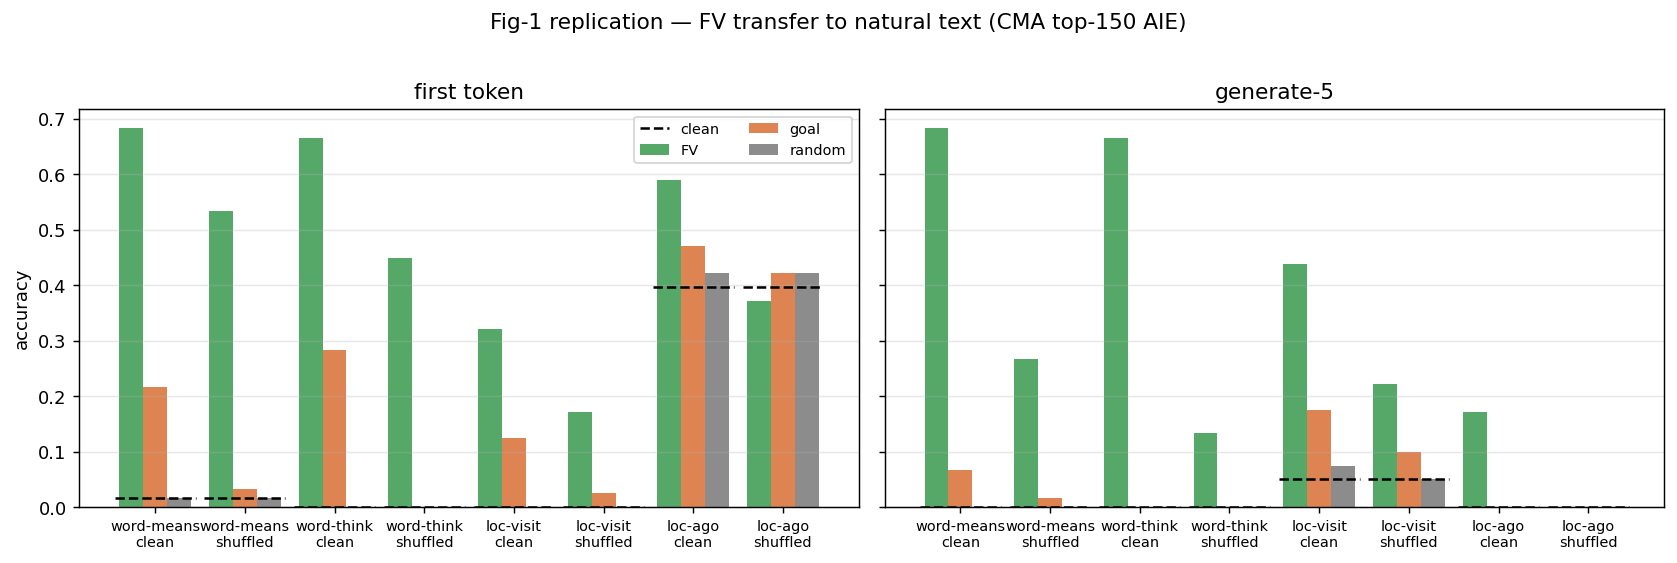

In [21]:
# ── §5 summary: mean over tasks, per (template, source, arm) ──
import matplotlib.pyplot as plt

CLEAN = nt_df[nt_df.arm == "clean"]
PATCH = nt_df[nt_df.arm != "clean"]
templates = list(dict.fromkeys(nt_df.template))
ARM_COLOR = {"FV": "#55a868", "goal": "#dd8452", "random": "#8c8c8c"}

for proto, col in [("first token (prefix)", "acc_first"), ("generate-5 (substring)", "acc_gen")]:
    tb = Table(title=f"§5 natural text — {proto}, mean over {nt_df.task.nunique()} tasks")
    tb.add_column("template"); tb.add_column("source")
    for a in NT_HEAD_SETS: tb.add_column(a, justify="right")
    tb.add_column("clean", justify="right")
    for tpl in templates:
        base = CLEAN[CLEAN.template == tpl][col].mean()
        for src in NT_SOURCES:
            sub = PATCH[(PATCH.template == tpl) & (PATCH.source == src)]
            tb.add_row(tpl, src,
                       *[f"{sub[sub.arm == a][col].mean():.2f}" for a in NT_HEAD_SETS],
                       f"{base:.2f}")
    rich_print(tb)

tb = Table(title="§5 mean dP(first answer token) — clean a-bar only")
tb.add_column("template")
for a in NT_HEAD_SETS: tb.add_column(a, justify="right")
for tpl in templates:
    sub = PATCH[(PATCH.template == tpl) & (PATCH.source == "clean")]
    tb.add_row(tpl, *[f"{sub[sub.arm == a].dP.mean():+.3f}" for a in NT_HEAD_SETS])
rich_print(tb)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=130, sharey=True)
for ax, (proto, col) in zip(axes, [("first token", "acc_first"), ("generate-5", "acc_gen")]):
    cells = [(t, s) for t in templates for s in NT_SOURCES]
    xs = np.arange(len(cells))
    w = 0.8 / len(NT_HEAD_SETS)
    for k, a in enumerate(NT_HEAD_SETS):
        ys = [PATCH[(PATCH.template == t) & (PATCH.source == s) & (PATCH.arm == a)][col].mean()
              for t, s in cells]
        ax.bar(xs + k * w - 0.4 + w / 2, ys, w, label=a, color=ARM_COLOR.get(a))
    for i, (t, s) in enumerate(cells):
        b = CLEAN[CLEAN.template == t][col].mean()
        ax.hlines(b, i - 0.45, i + 0.45, color="k", ls="--", lw=1.4,
                  label="clean" if i == 0 else None)
    ax.set_xticks(xs); ax.set_xticklabels([f"{t}\n{s}" for t, s in cells], fontsize=8)
    ax.set_title(proto); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("accuracy"); axes[0].legend(fontsize=8, ncol=2)
fig.suptitle(f"Fig-1 replication — FV transfer to natural text ({fv_desc})", y=1.02)
plt.tight_layout(); plt.show()

In [22]:
# ── §5 per-task breakdown (clean a-bar) + verbatim completions ──
piv = (nt_df[nt_df.source.isin(["clean", "-"])]
       .pivot_table(index=["task", "template"], columns="arm",
                    values=["acc_first", "acc_gen"]))
rich_print(piv.round(2))

SHOW = ("antonym", "clean", "FV")
rich_print(f"\n[bold]verbatim — task={SHOW[0]}  source={SHOW[1]}  arm={SHOW[2]}[/bold]")
for e in nt.examples:
    if (e["task"], e["source"], e["arm"]) != SHOW:
        continue
    rich_print(f"  [{e['template']}] {e['x']!r} -> {e['y']!r}")
    rich_print(f"      first  clean={e['clean_first']!r}   patch={e['patch_first']!r}")
    rich_print(f"      gen-5  clean={e['clean_gen']!r}\n             patch={e['patch_gen']!r}")

acc_first                    acc_gen              \
arm                                FV clean  goal random      FV clean  goal   
task             template                                                      
antonym          word-means      0.05  0.00  0.00   0.00    0.10   0.0  0.10   
                 word-think      0.00  0.00  0.00   0.00    0.10   0.0  0.00   
country-capital  loc-ago         0.75  0.65  0.80   0.70    0.20   0.0  0.00   
                 loc-visit       0.50  0.00  0.25   0.00    0.45   0.1  0.35   
landmark-country loc-ago         0.43  0.14  0.14   0.14    0.14   0.0  0.00   
                 loc-visit       0.14  0.00  0.00   0.00    0.43   0.0  0.00   
present-past     word-means      1.00  0.00  0.00   0.00    0.95   0.0  0.00   
                 word-think      1.00  0.00  0.00   0.00    0.90   0.0  0.00   
singular-plural  word-means      1.00  0.05  0.65   0.05    1.00   0.0  0.10   
                 word-think      1.00  0.00  0.85   0.00    1.00   0.0  0.00   

                                    
arm                         random  
task             template           
antonym          word-means   0.00  
                 word-think   0.00  
country-capital  loc-ago      0.00  
                 loc-visit    0.15  
landmark-country loc-ago      0.00  
                 loc-visit    0.00  
present-past     word-means   0.00  
                 word-think   0.00  
singular-plural  word-means   0.00  
                 word-think   0.00

verbatim — task=antonym  source=clean  arm=FV

'fore' -> 'aft'

first  clean='before'   patch='before'

gen-5  clean=' "before" or "'
             patch=' "after". This statement'

'ship' -> 'dock'

... (10 outputs left out)

gen-5  clean=' a large vessel that travels'
             patch=' a vessel. However,'

'distribution' -> 'concentration'

first  clean='the'   patch='spread'

gen-5  clean=' the way something is spread'
             patch=' the opposite of centralized.'